# Our Backtest Library

A worked example using the first two hours of our BTCUSDT LOB data.
The imbalance rule below demonstrates the API; it is not evidence of
profitable alpha. Orders use future executable quotes and include
illustrative fees, slippage, position limits, and displayed depth.

Install once if needed: `python -m pip install -e ./Backtest_Library[polars]`
from the HFT project root.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((
    base for base in (Path.cwd(), *Path.cwd().parents)
    if (base / "Backtest_Library").is_dir() and (base / "LOB").is_dir()
), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the HFT project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Backtest_Library import (
    BacktestConfig, run_backtest, plot_dashboard, plot_execution,
    plot_markouts, plot_win_rate,
)
OUTPUT_DIR = PROJECT_ROOT / "Backtest_Library" / "examples" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
DATA_PATH = PROJECT_ROOT / "LOB" / "processed" / "btcusdt_lob_1s.parquet"
quotes = pl.scan_parquet(DATA_PATH).head(7200).collect()
bid_qty = quotes["bid_qty"].to_numpy()
ask_qty = quotes["ask_qty"].to_numpy()
imbalance = (bid_qty - ask_qty) / (bid_qty + ask_qty)
target_positions = np.where(imbalance > 0.30, 0.001,
                            np.where(imbalance < -0.30, -0.001, 0.0))
target_positions[-5:] = 0.0
print(f"Input: {quotes.height:,} quotes; target units: BTC")
display(quotes.head(5))

Input: 7,200 quotes; target units: BTC


timestamp_utc,best_bid,bid_qty,best_ask,ask_qty,mid_price,spread,book_age_ms
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,i64
2026-09-24 00:00:01 UTC,84355.2,1.88,84355.3,3.068,84355.25,0.1,72
2026-09-24 00:00:02 UTC,84355.2,1.295,84355.3,3.781,84355.25,0.1,72
2026-09-24 00:00:03 UTC,84355.2,2.859,84355.3,2.221,84355.25,0.1,71
2026-09-24 00:00:04 UTC,84355.2,2.797,84355.3,2.356,84355.25,0.1,71
2026-09-24 00:00:05 UTC,84355.2,3.354,84355.3,1.664,84355.25,0.1,71


In [3]:
result = run_backtest(quotes, target_positions, config=BacktestConfig(
    initial_cash=10_000,
    fee_bps=5.0,            # Illustrative; use the actual venue/tier fee.
    slippage_bps=0.1,
    latency_ms=100,
    max_abs_position=0.001,
    max_quote_fraction=0.10,
))
selected = [
    "net_pnl", "total_return", "max_drawdown_pct", "closed_trades",
    "win_rate", "profit_factor", "fill_rate", "quantity_fill_ratio",
    "mean_execution_latency_ms", "daily_sharpe", "final_position",
]
display(result.summary().loc[selected].to_frame())
print("Ratios are fractions. Daily Sharpe is undefined for a two-hour sample.")
print("100 ms configured latency still fills on a later one-second quote.")

,value
net_pnl,-106.172471
total_return,-0.010617
max_drawdown_pct,0.010617
closed_trades,1272
win_rate,0.0
profit_factor,0.0
fill_rate,1.0
quantity_fill_ratio,0.979139
mean_execution_latency_ms,1000.0
daily_sharpe,None


Ratios are fractions. Daily Sharpe is undefined for a two-hour sample.
100 ms configured latency still fills on a later one-second quote.


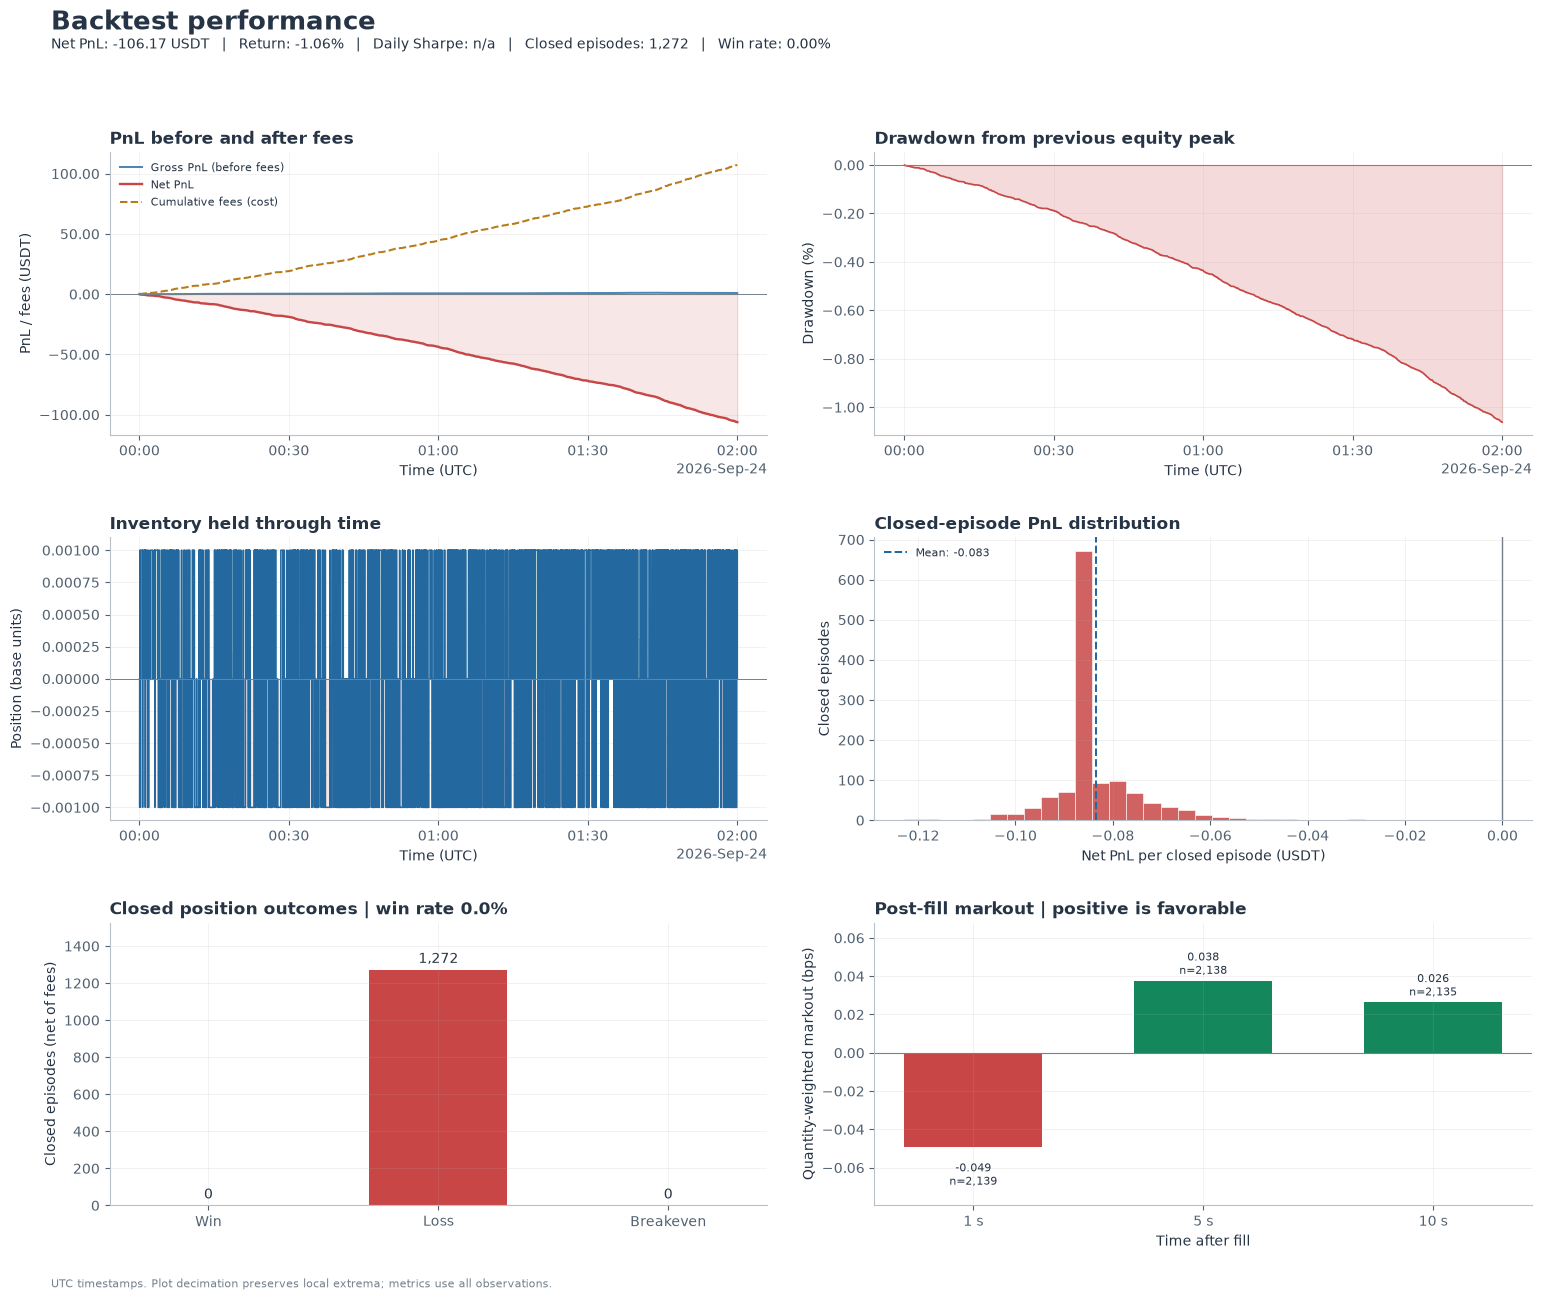

In [4]:
fig = plot_dashboard(result, save_path=OUTPUT_DIR / "dashboard.png")
display(fig)
plt.close(fig)

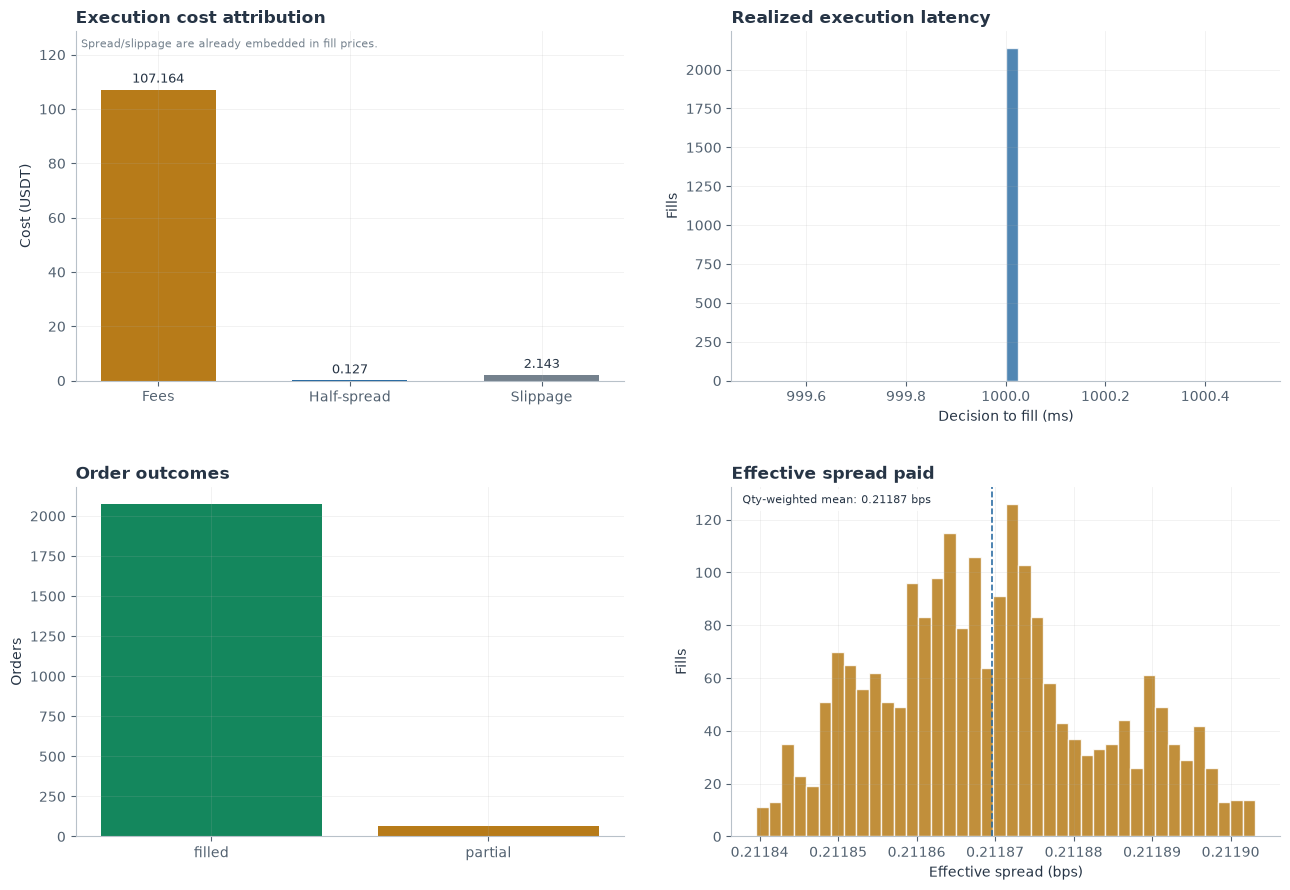

In [5]:
fig = plot_execution(result, save_path=OUTPUT_DIR / "execution.png")
display(fig)
plt.close(fig)

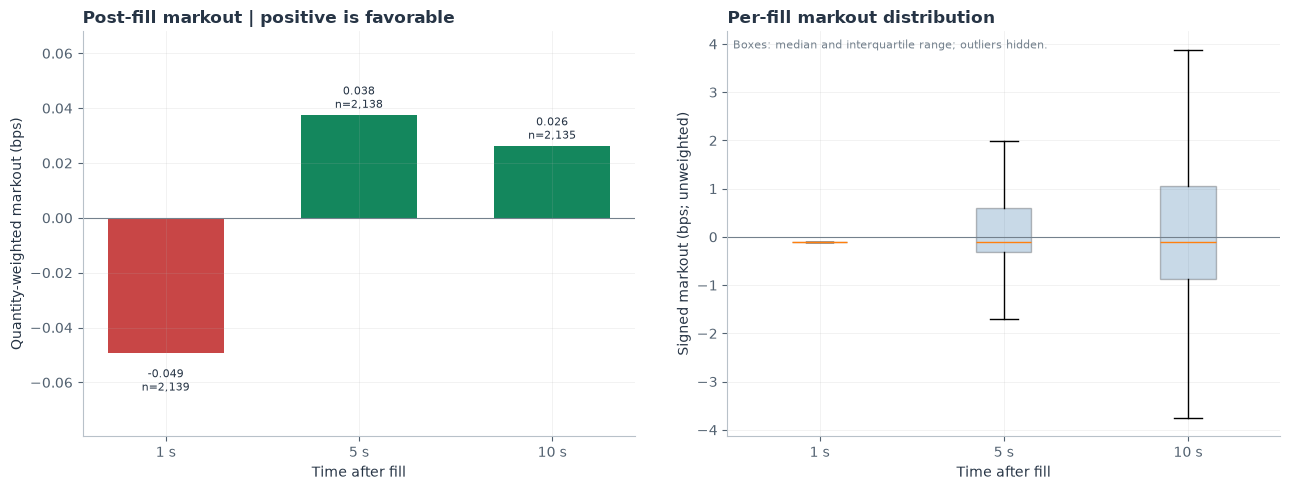

In [6]:
fig = plot_markouts(result, save_path=OUTPUT_DIR / "markouts.png")
display(fig)
plt.close(fig)

In [7]:
display(result.trades.head(10))
display(result.fills.head(10))
saved = result.save(OUTPUT_DIR / "report")
print("Saved ledgers:", ", ".join(saved))

,entry_time,exit_time,side,quantity,entry_price,exit_price,gross_pnl,fees,net_pnl,holding_seconds
0,2026-09-24 00:00:03+00:00,2026-09-24 00:00:04+00:00,short,0.001,84354.356448,84356.143553,-0.001787,0.084355,-0.086142,1.0
1,2026-09-24 00:00:06+00:00,2026-09-24 00:00:10+00:00,long,0.001,84356.143553,84354.356448,-0.001787,0.084355,-0.086142,4.0
2,2026-09-24 00:00:10+00:00,2026-09-24 00:00:12+00:00,short,0.001,84354.356448,84356.143553,-0.001787,0.084355,-0.086142,2.0
3,2026-09-24 00:00:16+00:00,2026-09-24 00:00:37+00:00,long,0.001,84356.143553,84377.256219,0.021113,0.084367,-0.063254,21.0
4,2026-09-24 00:00:38+00:00,2026-09-24 00:00:40+00:00,short,0.001,84377.256219,84388.603878,-0.011348,0.084383,-0.095731,2.0
5,2026-09-24 00:00:40+00:00,2026-09-24 00:01:01+00:00,long,0.001,84393.243924,84423.555756,0.030312,0.084408,-0.054097,21.0
6,2026-09-24 00:01:02+00:00,2026-09-24 00:01:06+00:00,long,0.001,84430.844300,84429.055701,-0.001789,0.084430,-0.086219,4.0
7,2026-09-24 00:01:11+00:00,2026-09-24 00:01:12+00:00,short,0.001,84404.755944,84406.544057,-0.001788,0.084406,-0.086194,1.0
8,2026-09-24 00:01:12+00:00,2026-09-24 00:01:15+00:00,long,0.001,84406.544057,84397.956012,-0.008588,0.084402,-0.092990,3.0
9,2026-09-24 00:01:18+00:00,2026-09-24 00:01:37+00:00,long,0.001,84399.743989,84396.856023,-0.002888,0.084398,-0.087286,19.0


,timestamp,decision_time,order_id,side,quantity,price,mid_price,fee,spread_cost,slippage_cost,latency_ms,is_liquidation,markout_bps_1000,markout_bps_5000,markout_bps_10000
0,2026-09-24 00:00:03+00:00,2026-09-24 00:00:02+00:00,0,sell,0.0010,84354.356448,84355.25,0.042177,0.00005,0.000844,1000.0,False,-0.105928,-0.105928,-0.105928
1,2026-09-24 00:00:04+00:00,2026-09-24 00:00:03+00:00,1,buy,0.0010,84356.143553,84355.25,0.042178,0.00005,0.000844,1000.0,False,-0.105926,-0.105926,-0.105926
2,2026-09-24 00:00:06+00:00,2026-09-24 00:00:05+00:00,2,buy,0.0010,84356.143553,84355.25,0.042178,0.00005,0.000844,1000.0,False,-0.105926,-0.105926,-0.105926
3,2026-09-24 00:00:10+00:00,2026-09-24 00:00:09+00:00,3,sell,0.0020,84354.356448,84355.25,0.084354,0.00010,0.001687,1000.0,False,-0.105928,-0.105928,-1.362532
4,2026-09-24 00:00:12+00:00,2026-09-24 00:00:11+00:00,4,buy,0.0010,84356.143553,84355.25,0.042178,0.00005,0.000844,1000.0,False,-0.105926,-0.105926,1.553704
5,2026-09-24 00:00:16+00:00,2026-09-24 00:00:15+00:00,5,buy,0.0010,84356.143553,84355.25,0.042178,0.00005,0.000844,1000.0,False,-0.105926,1.553704,1.553704
6,2026-09-24 00:00:37+00:00,2026-09-24 00:00:36+00:00,6,sell,0.0010,84377.256219,84378.15,0.042189,0.00005,0.000844,1000.0,False,-0.105927,-2.938444,-3.554723
7,2026-09-24 00:00:38+00:00,2026-09-24 00:00:37+00:00,7,sell,0.0010,84377.256219,84378.15,0.042189,0.00005,0.000844,1000.0,False,-0.414067,-3.175474,-3.756200
8,2026-09-24 00:00:39+00:00,2026-09-24 00:00:38+00:00,8,buy,0.0004,84381.643808,84380.75,0.016876,0.00002,0.000338,1000.0,False,1.268782,2.655340,3.520457
9,2026-09-24 00:00:40+00:00,2026-09-24 00:00:39+00:00,9,buy,0.0016,84393.243924,84392.35,0.067515,0.00008,0.001350,1000.0,False,1.043457,1.280443,2.358729


Saved ledgers: equity, fills, trades, orders, summary


For another strategy, replace `target_positions` with your own
base-asset targets, then call `run_backtest` again. Use only information
available at the decision timestamp when constructing those targets.

Available individual charts: `plot_pnl`, `plot_drawdown`,
`plot_inventory`, `plot_trade_distribution`, `plot_win_rate`,
`plot_execution`, and `plot_markouts`. All accept `save_path`.